# Tutorial T04 – Dimensionality reduction & clustering
*MIR & ML for Audio · TU Berlin · WiSe 2026/27*

In [28]:
# import standard packages you'll need

import sys
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import Audio, display

print(sys.executable)

# ─ add your own additional imports here:
import librosa
# additional plotting and visualizing functions
import seaborn as sns
# additional progress bar for process monitoring
from tqdm.auto import tqdm

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

/home/hallvard/miniforge3/envs/mirml/bin/python


In [29]:
# ── CONFIG ───────────────────────────────────────────────────────────────
CORPUS_DIR = Path("data") / "nu-disco-disco"   # ← name of your corpus folder
# ─────────────────────────────────────────────────────────────────────────
SESSION = "T04"
PREVIEW_DIR = CORPUS_DIR / "previews"
OUTPUT_DIR = Path("output") / SESSION      # results of this session
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert CORPUS_DIR.is_dir(), f"Not found: {CORPUS_DIR.resolve()} → check CORPUS_DIR"
CHART_CSV = next(CORPUS_DIR.glob("*.csv"))
print(CHART_CSV)

data/nu-disco-disco/Nu_Disco_Disco.csv


In [30]:
# Today we'll work with all tracks from one year of your choice (100 max.)
df_charts = pd.read_csv(CHART_CSV)

# Filter by your selected year:
year_tracks = (df_charts[(df_charts["year"] == 2022) & (df_charts["rank"] <= 100)]
            .dropna(subset=["beatport_track_id"])
            .drop_duplicates("beatport_track_id"))
year_tracks = year_tracks[[(PREVIEW_DIR / f"{int(i)}.mp3").exists() for i in year_tracks["beatport_track_id"]]]
year_tracks.info()

<class 'pandas.DataFrame'>
Index: 96 entries, 2202 to 2301
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               96 non-null     int64  
 1   rank               96 non-null     int64  
 2   points             96 non-null     int64  
 3   days_charted       96 non-null     int64  
 4   beatport_track_id  96 non-null     int64  
 5   title              96 non-null     str    
 6   mix                96 non-null     str    
 7   artist             96 non-null     str    
 8   label              96 non-null     str    
 9   duration_ms        96 non-null     float64
 10  subgenre           1 non-null      str    
 11  isrc               96 non-null     str    
 12  bpm                96 non-null     float64
 13  release_date       96 non-null     str    
dtypes: float64(2), int64(5), str(7)
memory usage: 11.2 KB


**Feature extraction**

Because loading a track (decoding, resampling etc.) and the STFT are usually the heaviest computations in this process, building a function to compute several features **per track** is probably the most efficient way!

**Your task: Build a function to compute 10 (numerical) features of your choice**

Be aware, that frame-level-features (e.g. librosa.feature.spectral_centroid) deliver an array with one value per frame! 

--> Use .mean(), .std() or np.median() to receive one value per track
--> Same counts for multidimensional (vector) features e.g. mfcc2 = librosa.feature.mfcc(y=y, sr=sr)[1].mean() 

In [31]:
# Build a function to compute 10 (numerical) features of your choice:


def track_features(track_id):
    y, sr = librosa.load(
        PREVIEW_DIR / f"{int(track_id)}.mp3"
    )  # 22.050 Hz, mono
    spectrum = np.abs(
        librosa.stft(y)
    )  # compute magnitude spectrogram once and reuse in spectral features (if needed)
    onset_env = librosa.onset.onset_strength(S=spectrum, sr=sr)  # compute onset
    rms = librosa.feature.rms(S=spectrum)[
        0
    ]  # compute rms once and reuse (if needed)
    mfcc = librosa.feature.mfcc(S=spectrum, sr=sr)

    # return a dictionary for each track:
    return {
        "rms_mean": rms.mean(),
        "onset_mean": onset_env.mean(),
        "mfcc_mean": mfcc[1].mean(),
    }

In [32]:
# Compute all features for the selected tracks and add them as new columns:
# [the tqdm function (wrapped around the loop object) is not mandatory, but gives you a progress bar 
# that's good for estimating the time needed for computing the features]

features = pd.DataFrame([track_features(i) for i in tqdm(year_tracks["beatport_track_id"])],
                        index=year_tracks.index)          # same row labels as year_tracks
year_tracks = year_tracks.join(features)


# add this step, if you wan't to save as new csv:
# year_tracks.to_csv(OUTPUT_DIR / "year_tracks_features.csv", index=False)

features.describe().round(2)

100%|██████████| 96/96 [01:46<00:00,  1.11s/it]


,rms_mean,onset_mean,mfcc_mean
count,96.00,96.00,96.00
mean,0.15,0.64,56.33
std,0.04,0.16,11.55
min,0.08,0.31,34.02
25%,0.13,0.52,49.55
50%,0.15,0.62,54.40
75%,0.18,0.75,64.45
max,0.22,1.11,91.45


**Standardizing**

-> (Almost) always mandatory for all models that work with distances, variances or gradients! 

-> Exceptions: Trees (e.g. Decision Tree, RandomForest), Supervised learning (scaling only on the training data)

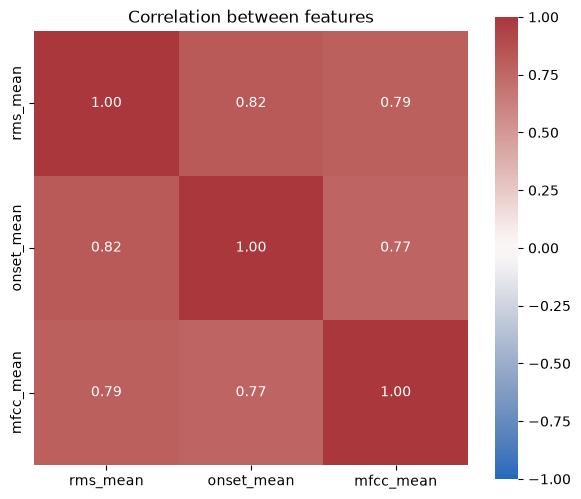

In [33]:
# Standardizing all features as the most important step (z-scores: mean 0, SD 1)
X = StandardScaler().fit_transform(features)

# plot the correlations between your computed features
fig, ax = plt.subplots(figsize=(7, 6))
# Seaborn has a built in function for heatmaps, pandas correlation matrix is computed from within:
sns.heatmap(features.corr(), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation between features")
plt.show()

**Dimensionality reduction**

... is not mandatory, but especially helpful for distance- or density-based models (e.g. k-means, kNN, GMM) 
and for linear/logistic regression with strongly correlated features (multicollinearity). 

Usually we use PCA for this -> See below

*Related:* **Factor analysis** (`sklearn.decomposition.FactorAnalysis`, optionally with `rotation="varimax"`) explains only the variance
that features share, aiming at interpretable latent constructs, while PCA summarises *all* variance.

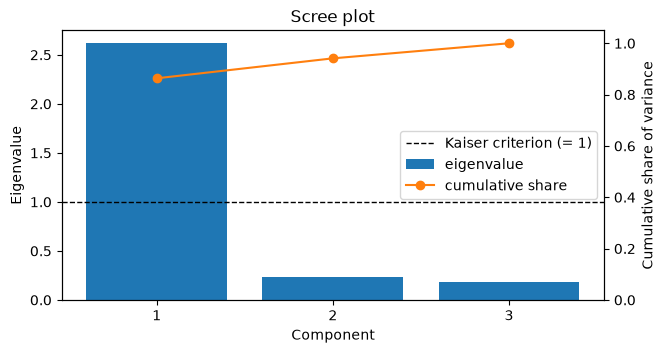

In [34]:
# PCA with all components: how much variance does each component explain?
pca_full = PCA().fit(X)

# Variance per component (standardised: 1 = one original feature) 
# -> If Eigenvalue < 1, the component explains less variance than a single feature
eigenvalues = pca_full.explained_variance_              
cum_share = pca_full.explained_variance_ratio_.cumsum()

# plot all components along with their Eigenvalue and explained variance within your full data
comp = np.arange(1, len(eigenvalues) + 1)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(comp, eigenvalues, label="eigenvalue")
ax.axhline(1, color="k", ls="--", lw=1, label="Kaiser criterion (= 1)")
ax2 = ax.twinx()
ax2.plot(comp, cum_share, "o-", color="tab:orange", label="cumulative share")
ax2.set(ylim=(0, 1.05), ylabel="Cumulative share of variance")
ax.set(xlabel="Component", ylabel="Eigenvalue", xticks=comp, title="Scree plot")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="center right")
plt.show()

**Alternative to the Kaiser-Criterion: Parallel analysis**

1. Create random data in the shape of your original data (e.g. 100 tracks x 10 features)
2. Compute PCA on random data and compare their eigenvalues with the eigenvalues of your original data

-> keep components whose Eigenvalue beats that of random data of the same size

In [35]:
# Parallel analysis as alternative decision for 
rng = np.random.default_rng(42)
random_ev = np.mean([PCA().fit(rng.standard_normal(X.shape)).explained_variance_ for _ in range(100)], axis=0)
pd.DataFrame({"eigenvalue": eigenvalues, "random": random_ev, "keep": eigenvalues > random_ev}, index=comp).round(2)

,eigenvalue,random,keep
1,2.62,1.23,True
2,0.24,1.00,False
3,0.18,0.80,False


Inspect the **loadings** of each component to get a feeling about what they "represent"

-> Loading = correlation of each feature with each component (r = -1 ... 1),
computed from the eigenvectors (`pca.components_`) × √eigenvalue on standardised data

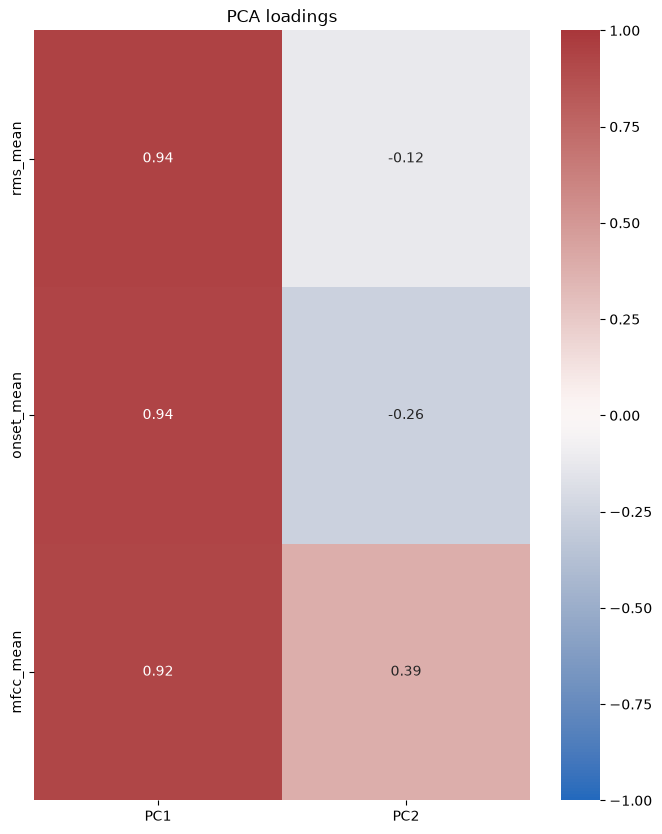

In [36]:
N_COMP = 2  # <-- select the number of components to keep, that your previous analysis suggested (Kaiser-Criterion / parallel analysis)
pca = PCA(n_components=N_COMP)
scores = pd.DataFrame(pca.fit_transform(X), index=features.index, columns=[f"PC{k}" for k in range(1, N_COMP + 1)])
loadings = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_),
                        index=features.columns, columns=scores.columns)

fig, ax = plt.subplots(figsize=(8, 10))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("PCA loadings")
plt.show()

**Silhouette scores** – how well does each track fit into its cluster?

  For every track:  
  - a = mean distance to the other tracks in its own cluster
  - b = mean distance to the tracks of the nearest other cluster
  - s = (b - a) / max(a, b)   → between -1 and 1

  s ≈ 1: clearly inside its cluster | s ≈ 0: on the border between two clusters | s < 0: closer to another cluster

  silhouette_score = mean s over all tracks → compare several k and prefer the highest

  Rule of thumb by Rousseeuw (1987): 
  - ">" 0.7 strong 
  - 0.5–0.7 reasonable 
  - 0.25–0.5 weak 
  - < 0.25 no real structure

  Limits: favours compact, round clusters (like k-means); compute it in the space you cluster in (here: PCA scores); check cluster sizes and listen before trusting a k -> Be sceptical as there's mostly not "the one solution"

In [37]:
# Now cluster your tracks (k-means) based on the PCA scores and compute their silhouette scores 
# -> which number of clusters fits best?

for k in range(2, 8):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(scores)
    print(k, round(silhouette_score(scores, labels), 3))

2 0.535
3 0.408
4 0.394
5 0.387
6 0.337
7 0.349


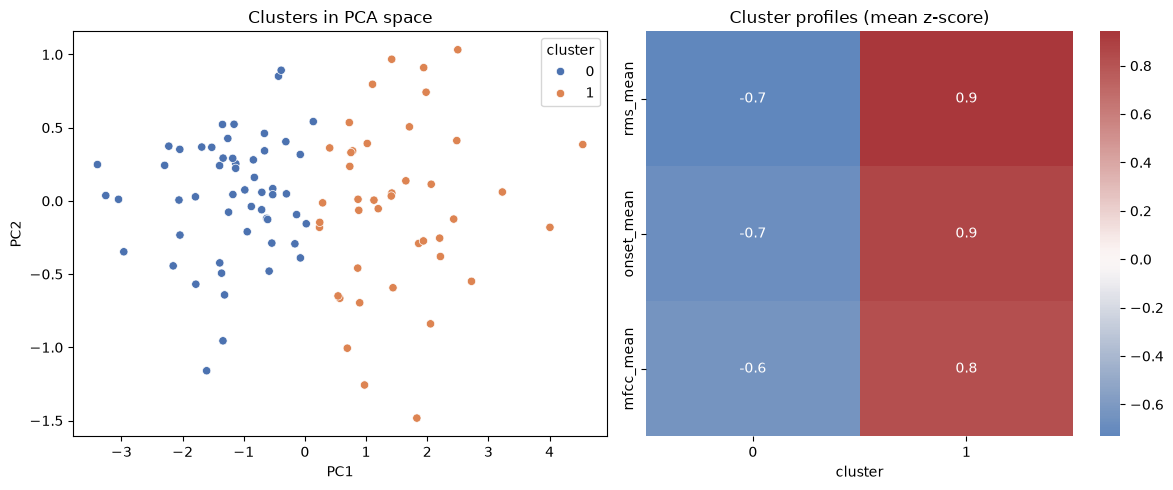

cluster
0    54
1    42
Name: count, dtype: int64

In [38]:
# Final clustering: plot and describe the clusters with the original (standardised) features
K = 2    # <-- select the "ideal" number of clusters based on the previous silhouette scores
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(scores)
scores["cluster"] = kmeans.labels_

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
sns.scatterplot(data=scores, x="PC1", y="PC2", hue="cluster", palette="deep", ax=ax1)
# group the cluster profiles based on the features mean z-score
profiles = pd.DataFrame(X, index=features.index, columns=features.columns).groupby(scores["cluster"]).mean()
sns.heatmap(profiles.T, annot=True, fmt=".1f", cmap="vlag", center=0, ax=ax2)

# # ... or show their profiles based on the features true mean scores: 
# profiles_orig = features.groupby(scores["cluster"]).mean()     # cluster means in original units (Hz, BPM, …)
# profiles_orig.round(2)
# sns.heatmap(profiles.T, annot=profiles_orig.T, fmt=".4g", cmap="vlag", center=0, ax=ax2)

ax1.set_title("Clusters in PCA space")
ax2.set_title("Cluster profiles (mean z-score)")
plt.tight_layout()
plt.show()
scores["cluster"].value_counts().sort_index()

In [39]:
# listen to the "most typical track" of each cluster (closest to the cluster centre) to get a better feeling of the previous process(es)
dist = kmeans.transform(scores[loadings.columns])       # distance of each track to each centre
for c in range(K):
    row = scores.index[dist[:, c].argmin()]               # row label of the closest track
    track_id = int(year_tracks.loc[row, "beatport_track_id"])
    print("Cluster", c, "–", year_tracks.loc[row, "artist"], "–", year_tracks.loc[row, "title"])
    display(Audio(filename=PREVIEW_DIR / f"{track_id}.mp3"))

Cluster 0 – Dave Lee ZR, Risqué Connection, Michael Gray – Saturday


Cluster 1 – Luca Debonaire, Maickel Telussa, Block & Crown – Be My Lover
